## Objectives

In this lab you will

- derive and check the gradient of the logistic cost;
- train logistic regression with gradient descent and compare the result with scikit-learn;
- see what goes wrong on perfectly separable data, and why scikit-learn regularises by default;
- train and evaluate a model on the breast-cancer data with scikit-learn, and choose the threshold.

## Tools

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals, no e-notation

def sigmoid(z):
    """Sigmoid function g(z) = 1 / (1 + exp(-z)), element by element (Lab 7)."""
    return 1.0 / (1.0 + np.exp(-z))

def compute_cost(X, y, w, b):
    """Logistic cost J(w, b), computed stably from z = X @ w + b (Lab 8)."""
    z = X @ w + b
    return np.mean(y * np.logaddexp(0, -z) + (1 - y) * np.logaddexp(0, z))

## Data

We use the two-class data from the lecture: $40$ examples of each class with two features, drawn around two different centres. The classes overlap, so no straight line separates them perfectly.

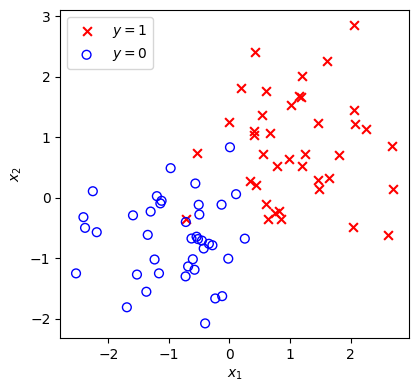

In [2]:
rng = np.random.default_rng(11)
X_train = np.vstack([rng.normal([-1.0, -0.6], 0.8, size=(40, 2)),     # class 0
                     rng.normal([1.0, 0.8], 0.8, size=(40, 2))])      # class 1
y_train = np.concatenate([np.zeros(40), np.ones(40)])

def plot_data(X, y, ax=None):
    """Plot two-feature data: red crosses for y = 1, blue circles for y = 0."""
    ax = plt.gca() if ax is None else ax
    ax.scatter(X[y == 1, 0], X[y == 1, 1], marker='x', c='r', s=40, label='$y = 1$')
    ax.scatter(X[y == 0, 0], X[y == 0, 1], marker='o', facecolor='none', edgecolor='b', s=40,
               label='$y = 0$')
    ax.set(xlabel='$x_1$', ylabel='$x_2$', aspect='equal')

plt.figure(figsize=(4.5, 4.5))
plot_data(X_train, y_train)
plt.legend()
plt.show()

## The gradient of the logistic cost

### The derivative of the sigmoid

The key fact from the lecture is
$$
g'(z) = g(z)\big(1 - g(z)\big).
$$
As in Labs 2 and 3, we check it against a central finite difference:

In [3]:
z = np.linspace(-6, 6, 13)
eps = 1e-6
g_prime_fd = (sigmoid(z + eps) - sigmoid(z - eps)) / (2 * eps)
print(f"largest difference: {np.max(np.abs(g_prime_fd - sigmoid(z) * (1 - sigmoid(z)))):.1e}")

largest difference: 7.2e-11


### Error times input

For one example, the loss is $L = -y\log f - (1 - y)\log(1 - f)$ with $f = g(z)$ and $z = \mathbf w\cdot\mathbf x + b$. By the chain rule,
$$
\frac{\partial L}{\partial z} = \frac{\partial L}{\partial f}\,\frac{\partial f}{\partial z}
= \frac{f - y}{f(1 - f)}\cdot f(1 - f) = f - y ,
$$
and since $\partial z/\partial w_j = x_j$ and $\partial z/\partial b = 1$, averaging over all examples gives
$$
\frac{\partial J}{\partial w_j} = \frac1m\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big)\,x_j^{(i)},
\qquad
\frac{\partial J}{\partial b} = \frac1m\sum_{i=1}^{m}\big(f_{\mathbf w,b}(\mathbf x^{(i)}) - y^{(i)}\big).
$$
These are the same formulas as for linear regression (Lab 3): **error times input**, averaged over the examples. What differs is the model inside them, $f_{\mathbf w,b}(\mathbf x) = g(\mathbf w\cdot\mathbf x + b)$ instead of $\mathbf w\cdot\mathbf x + b$.

In [4]:
def compute_gradient(X, y, w, b):
    """Gradient of the logistic cost: dJ/dw (shape (n,)) and dJ/db."""
    err = sigmoid(X @ w + b) - y          # f - y, shape (m,)
    return X.T @ err / len(y), np.mean(err)

# check against central finite differences, changing one parameter at a time
w_test, b_test = np.array([1.0, -2.0]), 0.5
dJ_dw, dJ_db = compute_gradient(X_train, y_train, w_test, b_test)
fd_w = np.array([(compute_cost(X_train, y_train, w_test + e, b_test)
                  - compute_cost(X_train, y_train, w_test - e, b_test)) / (2 * eps)
                 for e in eps * np.eye(2)])            # rows of eps * np.eye(2): eps * e_1, eps * e_2
fd_b = (compute_cost(X_train, y_train, w_test, b_test + eps)
        - compute_cost(X_train, y_train, w_test, b_test - eps)) / (2 * eps)
print(f"compute_gradient:   dJ/dw = {dJ_dw}, dJ/db = {dJ_db:.6f}")
print(f"finite differences: dJ/dw = {fd_w}, dJ/db = {fd_b:.6f}")

compute_gradient:   dJ/dw = [-0.479 -0.616], dJ/db = 0.074901
finite differences: dJ/dw = [-0.479 -0.616], dJ/db = 0.074901


## Gradient descent

Gradient descent updates all parameters simultaneously, $w_j \leftarrow w_j - \alpha\,\partial J/\partial w_j$ and $b \leftarrow b - \alpha\,\partial J/\partial b$. Compared with linear regression (Lab 3), only one line changes: the predictions are `sigmoid(X @ w + b)` instead of `X @ w + b`. This is the lecture's function, extended to record the cost:

In [5]:
def gradient_descent(X, y, alpha=0.5, n_iters=1000):
    """Batch gradient descent for logistic regression from w = 0, b = 0."""
    m, n = X.shape
    w, b = np.zeros(n), 0.0
    J_history = np.zeros(n_iters)
    for t in range(n_iters):
        J_history[t] = compute_cost(X, y, w, b)
        err = sigmoid(X @ w + b) - y          # (m,) errors
        w = w - alpha * X.T @ err / m         # simultaneous
        b = b - alpha * np.mean(err)          # update
    return w, b, J_history

w_gd, b_gd, J_hist = gradient_descent(X_train, y_train, alpha=0.5, n_iters=1000)
sk_model = LogisticRegression(C=1e10).fit(X_train, y_train)    # C=1e10: no regularisation
print(f"gradient descent: w = {w_gd}, b = {b_gd:.3f}")
print(f"scikit-learn:     w = {sk_model.coef_[0]}, b = {sk_model.intercept_[0]:.3f}")

gradient descent: w = [3.598 2.259], b = -0.197
scikit-learn:     w = [3.607 2.262], b = -0.198


As in the lecture, $1000$ iterations give $\mathbf w = (3.60, 2.26)$ and $b = -0.20$, the same as scikit-learn without regularisation; the small differences disappear with more iterations.

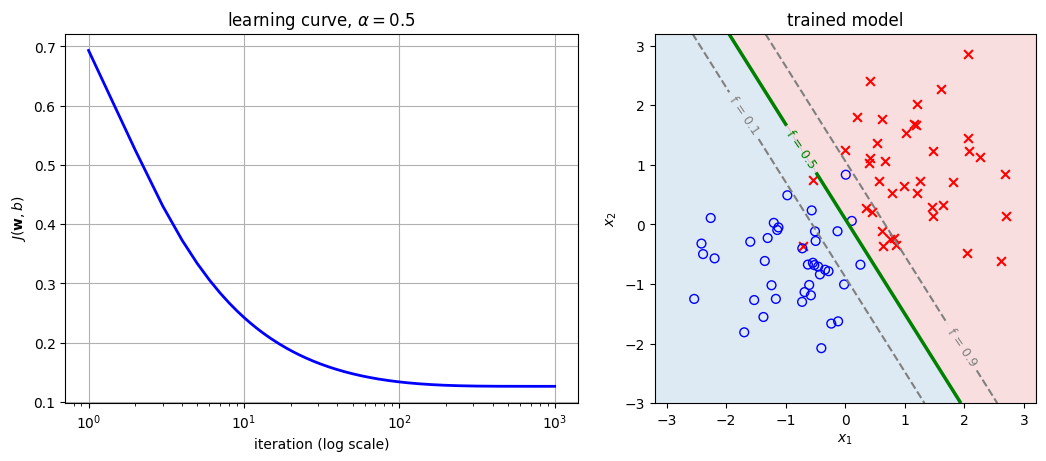

training accuracy: 0.950


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ax[0].semilogx(np.arange(1, len(J_hist) + 1), J_hist, 'b-', lw=2)
ax[0].set(xlabel='iteration (log scale)', ylabel='$J(\\mathbf{w}, b)$', title='learning curve, $\\alpha = 0.5$')
ax[0].grid(True)

g1, g2 = np.meshgrid(np.linspace(-3.2, 3.2, 300), np.linspace(-3, 3.2, 300))
F = sigmoid(w_gd[0] * g1 + w_gd[1] * g2 + b_gd)
ax[1].contourf(g1, g2, (F >= 0.5).astype(float), levels=[-0.5, 0.5, 1.5],
               colors=['tab:blue', 'tab:red'], alpha=0.15)
cs = ax[1].contour(g1, g2, F, levels=[0.1, 0.5, 0.9], colors=['grey', 'g', 'grey'],
                   linestyles=['--', '-', '--'], linewidths=[1.5, 2.5, 1.5])
ax[1].clabel(cs, fmt={0.1: 'f = 0.1', 0.5: 'f = 0.5', 0.9: 'f = 0.9'}, fontsize=9)
plot_data(X_train, y_train, ax=ax[1])
ax[1].set_title('trained model')
plt.show()

y_pred = (sigmoid(X_train @ w_gd + b_gd) >= 0.5).astype(int)
print(f"training accuracy: {np.mean(y_pred == y_train):.3f}")

- Left: $J$ decreases at every iteration and levels off, as it should. It does not reach $0$, because the classes overlap.
- Right: the decision boundary is the contour $f = 0.5$. Between the dashed contours $f = 0.1$ and $f = 0.9$ the model is uncertain, and this is exactly where the two classes overlap.

## Perfectly separable data

The tumour data of Lab 7 are **perfectly separable**: one point separates all benign tumours from all malignant ones. Let us run gradient descent on them for longer and longer:

In [7]:
x_tumour = np.array([0.6, 1.0, 1.4, 1.8, 2.2, 3.0, 3.4, 3.8, 4.2]).reshape(-1, 1)
y_tumour = np.array([0, 0, 0, 0, 0, 1, 1, 1, 1])

for n_iters in [1_000, 10_000, 100_000]:
    w_t, b_t, J_t = gradient_descent(x_tumour, y_tumour, alpha=1.0, n_iters=n_iters)
    print(f"{n_iters:7,d} iterations: w = {w_t[0]:6.2f}, b = {b_t:7.2f}, J = {J_t[-1]:.1e}, "
          f"boundary at x = {-b_t / w_t[0]:.2f}")

  1,000 iterations: w =   5.29, b =  -13.58, J = 2.9e-02, boundary at x = 2.57


 10,000 iterations: w =   9.88, b =  -25.54, J = 4.4e-03, boundary at x = 2.59


100,000 iterations: w =  15.38, b =  -39.86, J = 4.8e-04, boundary at x = 2.59


The boundary settles near $2.6$ cm, but $w$ and $b$ keep growing and $J$ keeps shrinking towards $0$. The reason: once a boundary separates the classes, multiplying $w$ and $b$ by a factor larger than $1$ keeps the boundary but makes the sigmoid steeper, so every prediction moves closer to its correct label and $J$ decreases. The cost therefore has **no minimum**, and gradient descent never stops improving.

scikit-learn behaves in the same way:

In [8]:
for C in [1e10, 1.0]:
    model = LogisticRegression(C=C, max_iter=1000).fit(x_tumour, y_tumour)
    w_sk, b_sk = model.coef_[0, 0], model.intercept_[0]
    print(f"scikit-learn, C = {C:g}: w = {w_sk:6.2f}, b = {b_sk:7.2f}, boundary at x = {-b_sk / w_sk:.2f}")

scikit-learn, C = 1e+10: w =  19.84, b =  -51.22, boundary at x = 2.58
scikit-learn, C = 1: w =   1.43, b =   -3.77, boundary at x = 2.63


- Without regularisation ($C = 10^{10}$), the solver simply stops at some large $(w, b)$ once the gradient is tiny.
- With the default regularisation ($C = 1$), the weights stay small and the solution is unique (Lecture 4).

All the boundaries lie near $2.6$ cm, but the parameters differ widely. On separable data, compare decision boundaries or predictions, not parameters.

## Logistic regression with scikit-learn

We finish with the lecture's scikit-learn workflow on the breast-cancer data, with two features: the mean radius and the mean texture.

In [9]:
cancer = load_breast_cancer()
X = cancer.data[:, :2]                  # mean radius, mean texture
y = 1 - cancer.target                   # 1 = malignant (scikit-learn codes it as 0)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

model = make_pipeline(StandardScaler(), LogisticRegression())
model.fit(X_tr, y_tr)
print(f"predicted classes: {model.predict(X_te[:3])}")
print(f"probabilities [P(y=0), P(y=1)]:\n{model.predict_proba(X_te[:3])}")
print(f"test accuracy:            {model.score(X_te, y_te):.3f}")
print(f"baseline (always benign): {np.mean(y_te == 0):.3f}")

predicted classes: [1 0 0]
probabilities [P(y=0), P(y=1)]:
[[0.041 0.959]
 [0.89  0.11 ]
 [0.81  0.19 ]]
test accuracy:            0.923
baseline (always benign): 0.629


- `train_test_split(..., stratify=y)` keeps the same fraction of malignant tumours in the training and test sets. The test set is used only for evaluation.
- The **pipeline** learns the scaling statistics on the training data and applies the same scaling to new data (Lab 4).
- `predict` uses the threshold $0.5$; `predict_proba` returns one column per class; `score` returns the **accuracy**, the fraction of correct predictions.
- Always compare with a **baseline**: predicting "benign" for every tumour is already right $62.9\%$ of the time. Our model reaches $92.3\%$; with all 30 features, $98.6\%$ (Challenge 4).

### Choosing the threshold

For a threshold other than $0.5$, compare the probabilities with $\tau$ yourself. We count both kinds of mistake on the test set:

- a **missed tumour**: a malignant tumour predicted benign ($y = 1$, $\hat y = 0$);
- a **false alarm**: a benign tumour predicted malignant ($y = 0$, $\hat y = 1$).

In [10]:
p_malignant = model.predict_proba(X_te)[:, 1]
for tau in [0.3, 0.5, 0.7]:
    y_hat = (p_malignant >= tau).astype(int)
    missed = np.sum((y_te == 1) & (y_hat == 0))
    false_alarms = np.sum((y_te == 0) & (y_hat == 1))
    print(f"tau = {tau}: accuracy {np.mean(y_hat == y_te):.3f}, "
          f"missed tumours {missed:2d}, false alarms {false_alarms:2d}")

tau = 0.3: accuracy 0.916, missed tumours  5, false alarms  7
tau = 0.5: accuracy 0.923, missed tumours  8, false alarms  3
tau = 0.7: accuracy 0.895, missed tumours 14, false alarms  1


A lower threshold misses fewer malignant tumours at the cost of more false alarms, while the accuracy hardly changes. In screening, a missed tumour is far worse than a false alarm, so a threshold below $0.5$ is sensible. Accuracy alone does not tell the whole story.

::: {.callout-note title="Regularisation and the shape of `coef_`"}
- `LogisticRegression` is **regularised** by default ($C = 1$). A very large $C$, such as `C=1e10`, switches regularisation off. The lecture's `C=np.inf` does the same, but scikit-learn 1.8 then prints a misleading warning. Older code uses `penalty=None`, which is deprecated since version 1.8.
- For two classes, `coef_` has shape `(1, n)` and `intercept_` has shape `(1,)`. Lab 10 covers more than two classes.
:::

## Challenges

1. Change the update to `w = w + alpha * X.T @ err / m` (and the same for `b`) and plot the learning curve. What do you see?
2. Train on the two-class data with $\alpha = 0.05$ and $\alpha = 5$, and plot both learning curves. What changes?
3. Use `gradient_descent` on the ten-example data of Lab 8. Do you reach the minimum $(w, b) \approx (1.35, -3.72)$?
4. Repeat the scikit-learn workflow with all 30 features (`cancer.data`). What is the test accuracy?
5. Find the largest threshold $\tau$ for which no malignant tumour in the test set is missed. How many false alarms does it cause?

## Summary

- Gradient of the logistic cost: $\partial J/\partial w_j = \frac1m\sum_i\big(f^{(i)} - y^{(i)}\big)x_j^{(i)}$, the same "error times input" as for linear regression, but with $f = g(\mathbf w\cdot\mathbf x + b)$.
- Gradient descent changes in one line only: `sigmoid(X @ w + b)`. Check the learning curve.
- On overlapping classes, gradient descent and unregularised scikit-learn agree. On perfectly separable data, $J$ has no minimum: the parameters grow without bound while the boundary settles. Regularisation (scikit-learn's default) makes the solution unique.
- scikit-learn: `make_pipeline(StandardScaler(), LogisticRegression())`, then `fit`, `predict`, `predict_proba` and `score`. Compare with a baseline and choose the threshold for the application.

**Next (Lab 10):** more than two classes.